In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
df = pd.read_csv("heart-disease-cleveland.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,diagnosis
0,63,1,1,145,233,1,2,150,0,2.3,3,0,6,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,3,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0


In [3]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   age         303 non-null    int64  
 1    sex        303 non-null    int64  
 2    cp         303 non-null    int64  
 3    trestbps   303 non-null    int64  
 4    chol       303 non-null    int64  
 5    fbs        303 non-null    int64  
 6    restecg    303 non-null    int64  
 7    thalach    303 non-null    int64  
 8    exang      303 non-null    int64  
 9    oldpeak    303 non-null    float64
 10   slope      303 non-null    int64  
 11   ca         303 non-null    object 
 12   thal       303 non-null    object 
 13   diagnosis  303 non-null    int64  
dtypes: float64(1), int64(11), object(2)
memory usage: 33.3+ KB


In [4]:
print("Columns:")
print(df.columns.tolist())

Columns:
['age', ' sex', ' cp', ' trestbps', ' chol', ' fbs', ' restecg', ' thalach', ' exang', ' oldpeak', ' slope', ' ca', ' thal', ' diagnosis']


In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
age           0
 sex          0
 cp           0
 trestbps     0
 chol         0
 fbs          0
 restecg      0
 thalach      0
 exang        0
 oldpeak      0
 slope        0
 ca           0
 thal         0
 diagnosis    0
dtype: int64


In [6]:
df = df.replace("?", np.nan)

for column in df.columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
age           0
 sex          0
 cp           0
 trestbps     0
 chol         0
 fbs          0
 restecg      0
 thalach      0
 exang        0
 oldpeak      0
 slope        0
 ca           4
 thal         2
 diagnosis    0
dtype: int64


In [12]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Separate features and target
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (303, 13)
Target shape: (303,)


In [11]:
print(df.columns.tolist())

['age', ' sex', ' cp', ' trestbps', ' chol', ' fbs', ' restecg', ' thalach', ' exang', ' oldpeak', ' slope', ' ca', ' thal', ' diagnosis']


In [13]:
# 0 = No Disease
# 1, 2, 3, 4 = Disease

y = y.apply(lambda value: 0 if value == 0 else 1)

print("Target Distribution:")
print(y.value_counts())

Target Distribution:
diagnosis
0    164
1    139
Name: count, dtype: int64


In [14]:
imputer = SimpleImputer(strategy="median")

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

print("Total missing values:", X.isnull().sum().sum())

Total missing values: 0


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (242, 13)
Testing data: (61, 13)


In [16]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [17]:
logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_scaled, y_train)

logistic_prediction = logistic_model.predict(X_test_scaled)

logistic_accuracy = accuracy_score(
    y_test,
    logistic_prediction
)

print("Logistic Regression Accuracy:",
      round(logistic_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 86.89 %


In [18]:
print(classification_report(
    y_test,
    logistic_prediction,
    target_names=["No Disease", "Disease"]
))

              precision    recall  f1-score   support

  No Disease       0.93      0.82      0.87        33
     Disease       0.81      0.93      0.87        28

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.88      0.87      0.87        61



In [19]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(X_train, y_train)

random_forest_prediction = random_forest_model.predict(X_test)

random_forest_accuracy = accuracy_score(
    y_test,
    random_forest_prediction
)

print("Random Forest Accuracy:",
      round(random_forest_accuracy * 100, 2), "%")

Random Forest Accuracy: 88.52 %


In [20]:
print(classification_report(
    y_test,
    random_forest_prediction,
    target_names=["No Disease", "Disease"]
))

              precision    recall  f1-score   support

  No Disease       0.93      0.85      0.89        33
     Disease       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



In [21]:
svm_model = SVC()

svm_model.fit(X_train_scaled, y_train)

svm_prediction = svm_model.predict(X_test_scaled)

svm_accuracy = accuracy_score(
    y_test,
    svm_prediction
)

print("SVM Accuracy:",
      round(svm_accuracy * 100, 2), "%")

SVM Accuracy: 85.25 %


In [22]:
print(classification_report(
    y_test,
    svm_prediction,
    target_names=["No Disease", "Disease"]
))

              precision    recall  f1-score   support

  No Disease       0.90      0.82      0.86        33
     Disease       0.81      0.89      0.85        28

    accuracy                           0.85        61
   macro avg       0.85      0.86      0.85        61
weighted avg       0.86      0.85      0.85        61



In [23]:
model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "SVM"
    ],
    "Accuracy": [
        logistic_accuracy,
        random_forest_accuracy,
        svm_accuracy
    ]
})

model_results["Accuracy (%)"] = (
    model_results["Accuracy"] * 100
)

print(model_results)

                 Model  Accuracy  Accuracy (%)
0  Logistic Regression  0.868852     86.885246
1        Random Forest  0.885246     88.524590
2                  SVM  0.852459     85.245902


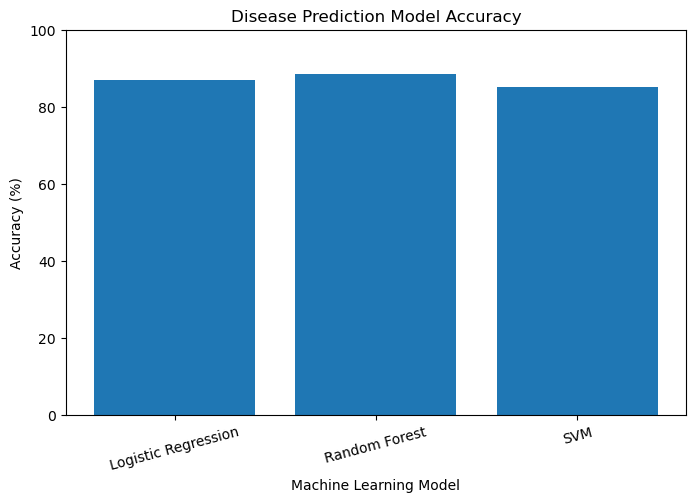

In [24]:
plt.figure(figsize=(8, 5))

plt.bar(
    model_results["Model"],
    model_results["Accuracy (%)"]
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")
plt.title("Disease Prediction Model Accuracy")

plt.ylim(0, 100)
plt.xticks(rotation=15)

plt.show()

In [25]:
accuracies = {
    "Logistic Regression": logistic_accuracy,
    "Random Forest": random_forest_accuracy,
    "SVM": svm_accuracy
}

best_model_name = max(
    accuracies,
    key=accuracies.get
)

print("Best Model:", best_model_name)
print(
    "Best Accuracy:",
    round(accuracies[best_model_name] * 100, 2),
    "%"
)

Best Model: Random Forest
Best Accuracy: 88.52 %


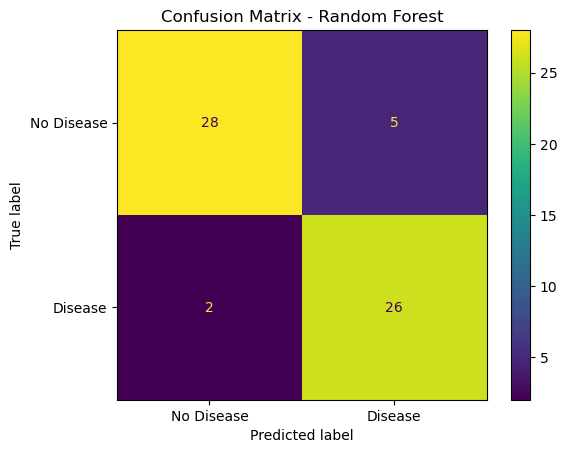

In [26]:
if best_model_name == "Logistic Regression":
    best_prediction = logistic_prediction

elif best_model_name == "Random Forest":
    best_prediction = random_forest_prediction

else:
    best_prediction = svm_prediction


cm = confusion_matrix(
    y_test,
    best_prediction
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Disease", "Disease"]
)

disp.plot()

plt.title("Confusion Matrix - " + best_model_name)
plt.show()

In [27]:
print("Final Model:", best_model_name)

print(
    "Final Accuracy:",
    round(accuracies[best_model_name] * 100, 2),
    "%"
)

print("\nFinal Classification Report:")

print(classification_report(
    y_test,
    best_prediction,
    target_names=["No Disease", "Disease"]
))

Final Model: Random Forest
Final Accuracy: 88.52 %

Final Classification Report:
              precision    recall  f1-score   support

  No Disease       0.93      0.85      0.89        33
     Disease       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



In [28]:
new_patient = pd.DataFrame([[
    55,
    1,
    3,
    140,
    250,
    0,
    1,
    150,
    0,
    1.0,
    2,
    0,
    3
]], columns=X.columns)

print(new_patient)

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   55    1   3       140   250    0        1      150      0      1.0      2   

   ca  thal  
0   0     3  


In [29]:
new_patient = pd.DataFrame(
    imputer.transform(new_patient),
    columns=X.columns
)

if best_model_name == "Random Forest":

    prediction = random_forest_model.predict(new_patient)

else:

    new_patient_scaled = scaler.transform(new_patient)

    if best_model_name == "Logistic Regression":
        prediction = logistic_model.predict(new_patient_scaled)

    else:
        prediction = svm_model.predict(new_patient_scaled)


if prediction[0] == 0:
    print("Prediction: No Disease")
else:
    print("Prediction: Disease")

Prediction: No Disease
